# Devoir maison 2 — carnets J3 et J4

> **À rendre avant la séance 5** — comme tout devoir, avant la première séance de la semaine
> suivante. Ce devoir porte sur **J3** (comparer sans se mentir, puis ce qu’on fait des défauts
> trouvés) et sur **J4** (la mesure, et la révélation). Il se fait **seul**, à la maison, et il se
> rend.

**Ce qu’on rend :** ce carnet, rempli, déposé dans votre **dépôt GitHub personnel** avec la
déclaration d’usage de l’IA (`declaration_DM2.md`). **Le journal de nettoyage** et **le tableau à
quatre colonnes** en sont les pièces principales.

**Pourquoi ce devoir :** chaque question demande une mesure que **vous** produisez — pas une
lecture. Si vous n’avez pas compris, ça se verra tout de suite ; c’est fait pour ça.

**Ce qui est lu.** Ce qui est lu ici : **les tableaux** et le code. Les tableaux : le tableau à quatre colonnes, le
journal de nettoyage, vos métriques. Le code : là où il produit un chiffre. **Ce dépôt est
relevé** : il est lu. Les **sept devoirs** comptent ensemble pour **10 % de la
note**. C'est la composante « exercices et devoirs » du cours (25 %, avec E1, E2, E3).
**Il n’y a pas d’oral sur les devoirs** : l’oral individuel, en fin de parcours, porte sur
l’ensemble de votre travail.

**Trois mots, pour être sûr :**

- **la baseline** — le modèle bête qu’il faut battre : la réponse constante, ou la règle du délai en
  place. Un score ne se lit jamais seul.
- **la barre de bruit** — de combien un score bouge tout seul ; en dessous, un écart n’est pas un
  gain.
- **le coût et le seuil** — ce que le métier paie pour chaque erreur, et le niveau de probabilité
  au-delà duquel on alerte.

---

## Comment ça marche

1. La partie **« Mise en place »** est **fournie** : exécutez-la, ne la modifiez pas. C’est elle
   qui lit les données, construit la table, mesure les baselines, la matrice et le coût — sans
   elle, aucune question ne peut tourner.
2. Chaque **question** porte sa consigne, un squelette et des **contrôles de forme**. Ils
   vérifient la forme de votre réponse : un pourcentage, une dimension, une cohérence avec
   vos autres réponses). Ils ne donnent **jamais** la réponse, et ils se taisent tant que vous
   n’avez pas écrit.
3. Une réponse se **chiffre** ou s’**écrit** — jamais « ça a marché ». **Deux** questions demandent
   d’**annoncer ce que vous attendez avant de mesurer** : c’est volontaire.
4. **Votre échantillon personnel** : dans la mise en place, remplacez `MON_IDENTIFIANT` par votre
   pseudo GitHub. Deux questions (Q9, Q10) se calculent **sur votre échantillon** : sans cela, vos
   chiffres sont ceux de tout le monde, et votre copie se recopie d’un voisin.
5. **Cœur** et **approfondissement** se rendent dans le **même dépôt**. La
   différence ne porte pas sur la note : elle dit où porter votre effort.
6. À la fin : les **trois tableaux**, puis le **dépôt**.

> **Ce qui est évalué, et ce qui se lit.** Trois objets traversent tout le cours, et on vous
> interrogera dessus — en devoir, au partiel, à l’oral. Le premier est la fonction `predict` :
> l’interface que le professeur appelle sur une table brute. Le deuxième est le **tableau d’essais** :
> ce que vous avez annoncé, essayé, mesuré. Le troisième est le **journal de nettoyage** : chaque
> décision, son choix, son effet mesuré. Ce qu’ils **retournent** est ce qu’on vous demandera de
> défendre — et votre projet s’appuiera dessus.


## Mise en place (fournie)

Exécutez cette partie **de haut en bas**, sans rien y modifier. Elle reprend la chaîne des
carnets : les données, la table, les baselines et la barre, la matrice de confusion, le
coût métier.

Les `random_state=0` sont la **graine du tirage au sort** (expliquée en
J1 §5). Le même nombre redonne le même découpage, donc la même mesure.


### Les outils


In [1]:
# les outils
# Aucun import en bloc au début : chaque module entre dans le carnet au moment de son premier
# usage. On voit ainsi à quoi il sert, au lieu de le deviner dans une liste.

# `display` : un tableau s'affiche proprement dans un carnet, et reste lisible ailleurs.
# C'est par `display` qu'on montre TOUTES les tables de ce carnet — jamais un print de texte.
try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)


### Les données


In [2]:
import os
import pandas as pd
# où sont les fichiers — on CHERCHE `train.csv`, on ne suppose pas un chemin
# (Kaggle a déjà déplacé ses points de montage : un chemin recopié se périme, une recherche non)
def _trouver_dossier(racines):
    """Première racine contenant train.csv — en surface, puis en profondeur."""
    for racine in racines:
        if not os.path.isdir(racine):
            continue
        if os.path.exists(os.path.join(racine, "train.csv")):
            return racine
        for chemin, _, fichiers in os.walk(racine):
            if "train.csv" in fichiers:
                return chemin
    return None

DOSSIER = _trouver_dossier(["/kaggle/input", "sortie"])
assert DOSSIER, "train.csv introuvable : les données de la compétition sont-elles montées ?"


In [3]:
train = pd.read_csv(os.path.join(DOSSIER, "train.csv"), low_memory=False)
test = pd.read_csv(os.path.join(DOSSIER, "test.csv"), low_memory=False)

ID, CIBLE = "ligne_id", "patient_absent"


### La table de travail


In [4]:
A_ECARTER = [ID, "dossier_id", "patient_id", "duree_consultation", "constantes_relevees",
             "motif_absence", "date_prise", "date_rdv", "taille_cm", "date_naissance",
             "canal_prise"]

def matrice(cols):
    """La table de travail : colonnes écartées retirées, catégorielles déclarées."""
    X = cols.drop(columns=[c for c in A_ECARTER + [CIBLE] if c in cols.columns]).copy()
    cat = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
    trop_fin = [c for c in cat if X[c].nunique() > 255]
    X = X.drop(columns=trop_fin)
    cat = [c for c in cat if c not in trop_fin]
    for c in cat:
        X[c] = X[c].fillna("").astype("category")
    return X, cat, trop_fin

X, CAT, TROP_FIN = matrice(train)
Xt, _, _ = matrice(test)

for c in CAT:
    Xt[c] = Xt[c].cat.set_categories(X[c].cat.categories)


### La cible, et la référence


In [5]:
repartition = pd.DataFrame({"lignes": [len(train), int(train[CIBLE].sum())],
                            "part (%)": [100.0, round(100 * train[CIBLE].mean(), 2)]},
                           index=["toutes", "absents"])

reference = 100 * max(train[CIBLE].mean(), 1 - train[CIBLE].mean())


In [6]:
# `y` entre ici ; la référence a déjà été calculée avec la distribution ci-dessus —
y = train[CIBLE]


### Le découpage, le modèle, et les baselines


In [7]:
# les baselines, sur le même jeu de validation — et la barre qui décide
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

Xtr, Xval, ytr, yval = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

# 1) la réponse constante : le concurrent le plus bête, et le plus dur à battre
constante = 100 * max(yval.mean(), 1 - yval.mean())

# 2) la règle du délai : « j'annonce une absence si le délai dépasse N jours ».
#    N se choisit sur les lignes d'apprentissage, pas sur celles de contrôle.
delai_max = int(Xtr['delai_jours'].max())
taux_par_seuil = {s: float(((Xtr['delai_jours'] > s).astype(int) == ytr).mean())
                  for s in (0, 1, 3, 7, 14, 30) if s < delai_max}
seuil_appris = max(taux_par_seuil, key=taux_par_seuil.get)
regle = (Xval['delai_jours'] > seuil_appris).astype(int)

# et la règle qui ne dirait jamais rien ? c'est la réponse constante, au point près
silence = (Xval['delai_jours'] > delai_max).astype(int)

# 3) la famille linéaire : elle a besoin de nombres, on lui en prépare — la recette des
#    séances précédentes (newton-cholesky : le solveur qui converge sur cette table)
X_n = pd.get_dummies(X, columns=CAT).fillna(0)   # 0 = trou comblé ; le linéaire ne lit pas les NaN
Xtr_n, Xval_n = X_n.loc[Xtr.index], X_n.loc[Xval.index]
lineaire = LogisticRegression(solver='newton-cholesky').fit(Xtr_n, ytr)

# 4) le modèle du cours, celui des séances précédentes
modele = HistGradientBoostingClassifier(random_state=0).fit(Xtr, ytr)

# la barre : l'erreur-type de l'exactitude sur CE jeu de validation
barre = 100 * ((constante / 100) * (1 - constante / 100) / len(yval)) ** 0.5

baselines = pd.DataFrame([
    {'baseline': 'toujours présent',
     'exactitude (%)': round(constante, 2)},
    {'baseline': f'règle du délai — absent si le délai dépasse {seuil_appris} j',
     'exactitude (%)': round(100 * (regle == yval).mean(), 2)},
    {'baseline': 'absent si ce patient a déjà manqué un rendez-vous',
     'exactitude (%)': round(100 * ((Xval['taux_absence_passe'] > 0).astype(int) == yval).mean(), 2)},
    {'baseline': 'la famille linéaire',
     'exactitude (%)': round(100 * lineaire.score(Xval_n, yval), 2)},
    {'baseline': 'le modèle du cours',
     'exactitude (%)': round(100 * modele.score(Xval, yval), 2)},
])

ecart = 100 * modele.score(Xval, yval) - constante


### La matrice de confusion, et les probabilités


In [8]:
# les quatre cases, comptées à la main sur le jeu de contrôle
predit = modele.predict(Xval)

VP = int(((predit == 1) & (yval == 1)).sum())   # annoncé absent, et absent
FP = int(((predit == 1) & (yval == 0)).sum())   # annoncé absent, et venu : la fausse alerte
FN = int(((predit == 0) & (yval == 1)).sum())   # annoncé présent, et absent : l’absence manquée
VN = int(((predit == 0) & (yval == 0)).sum())   # annoncé présent, et venu

assert VP + FP + FN + VN == len(yval)

# et la probabilité, qui servira à déplacer le seuil : c’est elle qui décide, pas le 0/1
probabilites = modele.predict_proba(Xval)[:, 1]

# les quatre mêmes cases, retrouvées par la bibliothèque — le contrôle, pas la confiance
from sklearn.metrics import confusion_matrix
confirme = confusion_matrix(yval, predit).ravel()          # ordre : VN, FP, FN, VP
assert (VN, FP, FN, VP) == tuple(int(v) for v in confirme), 'les quatre cases ne concordent pas'


### Le coût métier


In [9]:
# le coût d’une décision, et la dérivation du seuil
COUT_FP, COUT_FN = 25, 100   # les deux montants de l’énoncé, en unités de coût

def cout(decision, verite=yval):
    faux_positifs = int(((decision == 1) & (verite == 0)).sum())
    faux_negatifs = int(((decision == 0) & (verite == 1)).sum())
    return COUT_FP * faux_positifs + COUT_FN * faux_negatifs

seuil_theorique = COUT_FP / (COUT_FP + COUT_FN)


### Les outils du nettoyage


In [10]:
# un trou aléatoire : cinq traitements, et ce que chacun change
def score_de(Xe, ye=None):
    """Entraîne et mesure, toujours sur la même découpe."""
    ye = y if ye is None else ye
    Xtr_m, Xval_m, ytr_m, yval_m = train_test_split(Xe, ye, test_size=0.2, stratify=ye, random_state=0)
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(Xtr_m, ytr_m).score(Xval_m, yval_m)

# le même découpage, les lignes retirées seulement côté apprentissage : le jeu de contrôle
# ne change pas, donc les deux scores se comparent vraiment — ce que `score_de` ne fait pas
def score_sans_lignes(masque):
    """Retire des lignes du seul côté apprentissage, et mesure sur le même jeu de contrôle."""
    garde = masque.loc[Xtr.index]
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(
        Xtr[garde], ytr[garde]).score(Xval, yval)


In [11]:
# les colonnes inutiles, et la raison de chacune
raisons = {
    "zone_clinique": "une seule valeur sur toute la table",
    "indice_meteo_jour": "du bruit pur",
    "score_territorial": "42 052 valeurs, aucune raison de croire qu’elles disent quelque chose",
    "age_mois": "age_mois ÷ 12 = age — sur 100 % des lignes (mesuré en J1, 2.6)",
    "cout_acte": "montant_acte = 13,68 × cout_acte, rapport constant (mesuré en J1, 2.6)",
}
inutiles = [c for c in raisons if c in X.columns]


In [12]:
# le journal de nettoyage — ce qui est lu n’est pas le score, c’est le tableau
JOURNAL = []

def journal(decision, choix, raison, effet):
    """Une décision, le choix fait, la raison qu’on donnerait à un audit, et l’effet mesuré
       en points — avec la comparaison au double de la barre, qui dit si l’effet compte."""
    JOURNAL.append({"décision": decision, "choix": choix, "raison (sans le score)": raison,
                    "effet mesuré": round(effet, 2),
                    "> double de la barre ?": "oui" if abs(effet) > 2 * barre else "non"})
    display(pd.DataFrame(JOURNAL))


### Le pipeline, et le fichier à envoyer


In [13]:
# le pipeline : de la table brute à la prédiction, en un seul endroit
# Même contrat que `predict` : une table brute entre, un 0/1 par ligne sort.
def nettoyer(brut):
    """Les décisions apprises sur la table d’apprentissage, appliquées à une table brute :
       colonnes inutiles écartées, colonnes trop fines écartées, et les catégories de
       l’apprentissage — jamais recalculées sur la table qu’on reçoit."""
    d = matrice(brut)[0]
    d = d.drop(columns=[c for c in inutiles if c in d.columns])
    d = d[[c for c in X.columns if c in d.columns]]
    for c in CAT:
        if c not in d.columns:
            continue
        d[c] = d[c].astype("category").cat.set_categories(X[c].cat.categories)
    return d

def pipeline(brut):
    """Reçoit une table brute et rend un tableau de 0/1 — la chaîne complète."""
    return modele_final.predict(nettoyer(brut)).astype(int)

X_propre = nettoyer(train)
modele_final = HistGradientBoostingClassifier(random_state=0).fit(X_propre, y)

soumission = pd.DataFrame({ID: test[ID], CIBLE: pipeline(test)})
soumission.to_csv("submission.csv", index=False)


### Le rituel : annoncer avant de mesurer


In [14]:
# l'horloge entre ici : c'est elle qui rend une prédiction vérifiable
from datetime import datetime

ESSAIS = []
PREDICTIONS = []

def prevoir(essai, attendu, raison):
    """Écrit ce que vous attendez AVANT de mesurer — horodaté.
       `noter(...)` refuse ensuite tout essai sans prédiction : l'ordre n'est pas demandé, il est
       appliqué. Ce que cette fonction garantit, exactement : une prédiction EXISTAIT avant que la
       ligne du tableau soit écrite. Elle ne date pas la mesure — le score lui arrive déjà calculé.
       Pour la garantie complète, mesurez dans `essai(...)`, qui date la mesure lui-même."""
    PREDICTIONS[:] = [p for p in PREDICTIONS if p["essai"] != essai]
    PREDICTIONS.append({"essai": essai, "attendu": attendu, "raison": raison,
                        "écrit à": datetime.now().strftime("%H:%M:%S")})
    display(pd.DataFrame(PREDICTIONS))

def essai(nom, mesure, changement="", attendu=""):
    """Le chemin STRICT : la mesure est prise ICI, donc l'ordre (prédiction puis mesure) est prouvé.
       `mesure` est une fonction sans argument qui rend le score, par exemple
       `lambda: modele.score(Xval, yval)`. Refuse de mesurer sans prédiction."""
    prevu = [p for p in PREDICTIONS if p["essai"] == nom]
    if not prevu:
        print(f"refusé : aucune prédiction pour « {nom} ». Écrivez prevoir(...) d'abord.")
        return None
    score = 100 * mesure()
    noter(nom, changement or "voir la question", attendu or prevu[0]["attendu"], score)
    return score

def noter(hypothese, changement, attendu, score):
    """Ajoute une ligne au tableau. `attendu` : un signe et une raison, jamais une valeur.
       Ré-exécuter une cellule REMPLACE la ligne de même `hypothèse` : elle ne la double pas.

       REFUSE d'enregistrer un essai non annoncé — c'est la règle du cours, appliquée.
       Ce qu'elle garantit, et rien de plus : une prédiction existait AVANT que cette ligne soit
       écrite. Elle ne date pas la mesure — d'où `essai(...)` pour la garantie complète."""
    prevu = [p for p in PREDICTIONS if p["essai"] == hypothese]
    if not prevu:
        print(f"  refusé : aucune prédiction pour « {hypothese} ».")
        print("  Écrivez prevoir(...) d'abord — l'ordre est vérifié, pas seulement demandé.")
        return
    ligne = {"hypothèse": hypothese, "changement": changement,
             "attendu": attendu, "mesuré": round(score, 2),
             "prédiction écrite avant ?": "oui, à " + prevu[0]["écrit à"]}
    ESSAIS[:] = [e for e in ESSAIS if e["hypothèse"] != hypothese] + [ligne]
    display(pd.DataFrame(ESSAIS))


### Votre échantillon personnel — **à personnaliser**

Deux questions se calculent sur un **échantillon qui n’appartient qu’à vous** : il est tiré de
votre identifiant. Il fait la moitié du jeu de contrôle. Remplacez la ligne `MON_IDENTIFIANT`
par votre pseudo GitHub, puis exécutez la cellule : elle affiche la taille de votre échantillon et
sa graine. Le reste de la mise en place, lui, ne se modifie pas.


In [31]:
# ── votre échantillon personnel : il ne change que les chiffres que vous devez produire
import zlib

MON_IDENTIFIANT = "Reussite-ui "   # ← en minuscules, sans espace
graine_perso = zlib.crc32(MON_IDENTIFIANT.strip().lower().encode())
positions = Xval.sample(frac=0.5, random_state=graine_perso).index
ou = Xval.index.get_indexer(positions)
Xval_perso, yval_perso, proba_perso = Xval.loc[positions], yval.loc[positions], probabilites[ou]

print(f"votre échantillon personnel : {len(positions)} lignes (la moitié du jeu de contrôle), graine {graine_perso}")
if "remplacez" in MON_IDENTIFIANT:
    print("  ⚠ remplacez MON_IDENTIFIANT par votre pseudo : sinon votre échantillon est celui de tout le monde.")


votre échantillon personnel : 14990 lignes (la moitié du jeu de contrôle), graine 3331248613


### Les vérifications, et le tableau d’essais


In [16]:
def phrases(reponse):
    """Une réponse de prose peut arriver en liste, en Series ou en table : on la ramène à des phrases."""
    if hasattr(reponse, "to_dict"):
        return [str(v) for ligne in reponse.to_dict("records") for v in ligne.values()]
    return [str(p) for p in reponse]

VERIFICATIONS = []

def verifier(nom, condition, indice=''):
    """Contrôle silencieux : il ne dit jamais la valeur attendue."""
    VERIFICATIONS.append({'contrôle': nom, 'tient': bool(condition)})
    print(('  ok        ' if condition else '  À REVOIR  ') + nom
          + ('' if condition else '   ->   ' + indice))

def controle(nom, quoi, indice=''):
    """Contrôle de forme, posé dans la cellule de la question. Il ne compare jamais à une valeur
       attendue : un type, une plage, une dimension, ou une cohérence avec vos autres réponses.
       Tant que la réponse n’est pas écrite, il se tait."""
    try:
        ok = bool(quoi())
    except NameError:
        print(f'  (pas encore écrit)  {nom}')
        return
    except Exception as e:
        print(f'  REVOIR    {nom}   ->   {type(e).__name__} : {e}')
        return
    VERIFICATIONS.append({'contrôle': nom, 'tient': ok})
    print(('  ok        ' if ok else '  REVOIR    ') + nom + ('' if ok else '   ->   ' + indice))

# le tableau d'essais et son `noter` strict viennent de la mise en place (extraits de J1) :
# il refuse un essai non annoncé. Le devoir n'en redéfinit pas un second, plus permissif.


### La mise en place est-elle prête ?


In [17]:
# sept vérifications d'état — elles portent sur la mise en place, pas sur vos réponses
verifier('les données sont chargées', len(train) > 100_000)
verifier('la table de travail est construite', 'patient_absent' not in X.columns)
verifier('le découpage est fait, le modèle ajusté', len(probabilites) == len(yval))
verifier('les baselines sont mesurées', constante > 50 and barre > 0)
verifier('votre échantillon personnel est prêt', len(yval_perso) > 1000)
verifier('le pipeline tourne sur une table brute', len(pipeline(test.head(50))) == 50)
verifier('le fichier est écrit', os.path.exists('submission.csv'))


  ok        les données sont chargées
  ok        la table de travail est construite
  ok        le découpage est fait, le modèle ajusté
  ok        les baselines sont mesurées
  ok        votre échantillon personnel est prêt
  ok        le pipeline tourne sur une table brute
  ok        le fichier est écrit


## Les questions

**Douze questions : dix de cœur, deux d’approfondissement.** Elles suivent l’ordre des
carnets — J3 d’abord (comparer, puis nettoyer), J4 ensuite (la mesure). Pour chacune : lisez
la consigne, écrivez votre code (ou votre phrase) à l’emplacement prévu, et **exécutez la
cellule** — c’est l’exécution qui déclenche les contrôles.


### Question 1 — Une baseline de votre main, et sa place dans le tableau  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le carnet J3 a mesuré **ses** baselines. La vôtre doit être la vôtre.

**Consigne.**
  1. choisissez une colonne que **ni la réponse constante ni la règle du délai du carnet**
     (`delai_jours`) n'utilise. Écrivez la règle en une phrase : quel signal, quelle décision ;
  2. mesurez son exactitude sur le jeu de validation (`Xval`, `yval`) ;
  3. divisez son écart à `constante` — la réponse constante, **81,75 %** — par `barre` : combien
     d'erreurs-types cela fait-il ?

**Livrables.** `ma_regle` · `ma_baseline` · `mes_erreurs_types`.

**Critère de réussite.** Une règle qui **égale ou dépasse** la constante est un résultat — dites-le.
Un écart sous une barre n'est pas un gain.

*≈ 20 min.*


In [32]:
for col in ['hypertension', 'diabete', 'alcoolisme', 'handicap',
            'rappel_envoye', 'charge_chronique']:
    for valeur in Xval[col].dropna().unique():
        for prediction in [0, 1]:
            masque = Xval[col] == valeur
            score = 100 * (yval[masque] == prediction).mean()
            print(col, "=", valeur, "→", prediction, ":", round(score, 2), "%")

hypertension = 0 → 0 : 81.71 %
hypertension = 0 → 1 : 18.29 %
hypertension = 1 → 0 : 81.93 %
hypertension = 1 → 1 : 18.07 %
diabete = 0 → 0 : 81.77 %
diabete = 0 → 1 : 18.23 %
diabete = 1 → 0 : 81.54 %
diabete = 1 → 1 : 18.46 %
alcoolisme = 0 → 0 : 81.74 %
alcoolisme = 0 → 1 : 18.26 %
alcoolisme = 1 → 0 : 82.06 %
alcoolisme = 1 → 1 : 17.94 %
handicap = 0 → 0 : 81.72 %
handicap = 0 → 1 : 18.28 %
handicap = 1 → 0 : 83.19 %
handicap = 1 → 1 : 16.81 %
rappel_envoye =  → 0 : 86.68 %
rappel_envoye =  → 1 : 13.32 %
rappel_envoye = envoyé → 0 : 71.84 %
rappel_envoye = envoyé → 1 : 28.16 %
charge_chronique = 0 → 0 : 81.71 %
charge_chronique = 0 → 1 : 18.29 %
charge_chronique = 1 → 0 : 81.71 %
charge_chronique = 1 → 1 : 18.29 %
charge_chronique = 2 → 0 : 83.91 %
charge_chronique = 2 → 1 : 16.09 %
charge_chronique = 3 → 0 : 70.83 %
charge_chronique = 3 → 1 : 29.17 %
charge_chronique = 4 → 0 : 50.0 %
charge_chronique = 4 → 1 : 50.0 %


In [33]:
prediction = Xval['charge_chronique'].isin([3, 4]).astype(int)

ma_baseline = 100 * (prediction == yval).mean()

mes_erreurs_types = (ma_baseline - constante) / barre

print("Exactitude :", round(ma_baseline, 2), "%")
print("Écart en erreurs-types :", round(mes_erreurs_types, 2))

Exactitude : 81.72 %
Écart en erreurs-types : -0.15


In [34]:
ma_regle = "Si charge_chronique vaut 3 ou 4, je prédis une absence ; sinon je prédis une présence."

ma_baseline = 81.72

mes_erreurs_types = -0.15

controle('la règle est écrite', lambda: len(ma_regle) > 40,
         'décrivez la colonne et la décision en une phrase')
controle('une exactitude en pourcentage', lambda: 0 < ma_baseline <= 100,
         'un pourcentage (0 à 100), pas une proportion')
controle('un écart exprimé en erreurs-types', lambda: 0 <= abs(mes_erreurs_types) < 30,
         'divisez votre écart par la barre')


  ok        la règle est écrite
  ok        une exactitude en pourcentage
  ok        un écart exprimé en erreurs-types


### Question 2 — Le classement affiché tient-il ?  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, douze variantes jugées sur 1 000 lignes affichées ne se retrouvaient pas sur
celles jamais montrées. L'**affichage** est l'échantillon sur lequel le classement se lit ; le reste, celui qu'on
ne regarde pas avant de mesurer.

**Consigne.**
  1. annoncez **avant** de mesurer : le premier de l’affichage sera-t-il aussi le premier des lignes jamais montrées ?
  2. pour cette question, mettez **4 000 lignes de côté dans `Xtr`, avant d’entraîner** : elles ne servent ni à
     l’apprentissage, ni au choix des réglages. Coupez-les en 1 000 pour l’affichage et 3 000 jamais
     montrées (`train_test_split`, `random_state=0`) ;
  3. faites varier **six** réglages de votre choix, chacun entraîné sur les lignes qui restent — et dites **ce qui varie** (le nombre
     d'itérations ? la profondeur ? les deux ?) ;
  4. mesurez. Le premier de l’affichage est la variante qui a le meilleur score sur les 1 000.
     Donnez son **rang** parmi les lignes jamais montrées (1 = premier).

**Livrables.** `mon_annonce` · `score_affiche_premier` · `score_jamais_montre_premier` · `rang_jamais_montre_premier`.

**Critère de réussite.** Un seul tirage ne prouve pas qu'« un classement tient » : il montre **ce**
tirage-là. Dites ce que vous pouvez conclure, et ce que vous ne pouvez pas.

*≈ 25 min.*


In [35]:



mon_annonce = "Je pense que le premier modèle sur les lignes affichées ne sera pas forcément le premier sur les lignes jamais montrées."


Xtr_reste, X_reserve, ytr_reste, y_reserve = train_test_split(
    Xtr,
    ytr,
    test_size=4000,
    random_state=0,
    stratify=ytr
)

X_affiche, X_jamais, y_affiche, y_jamais = train_test_split(
    X_reserve,
    y_reserve,
    test_size=3000,
    random_state=0,
    stratify=y_reserve
)


reglages = [
    {"max_iter": 50, "max_leaf_nodes": 7},
    {"max_iter": 100, "max_leaf_nodes": 7},
    {"max_iter": 200, "max_leaf_nodes": 7},
    {"max_iter": 50, "max_leaf_nodes": 15},
    {"max_iter": 100, "max_leaf_nodes": 15},
    {"max_iter": 200, "max_leaf_nodes": 15}
]

resultats = []

for numero, reglage in enumerate(reglages, start=1):

    modele_test = HistGradientBoostingClassifier(
        random_state=0,
        **reglage
    )

    modele_test.fit(Xtr_reste, ytr_reste)

    score_affiche = 100 * modele_test.score(X_affiche, y_affiche)

    score_jamais = 100 * modele_test.score(X_jamais, y_jamais)

    resultats.append({
        "modèle": numero,
        "itérations": reglage["max_iter"],
        "profondeur": reglage["max_leaf_nodes"],
        "score affiché": score_affiche,
        "score jamais montré": score_jamais
    })

tableau_resultats = pd.DataFrame(resultats)

display(tableau_resultats)

meilleur_affiche = tableau_resultats["score affiché"].idxmax()

premier_modele = tableau_resultats.loc[meilleur_affiche]

score_affiche_premier = round(premier_modele["score affiché"], 2)

score_jamais_montre_premier = round(
    premier_modele["score jamais montré"], 2
)

rang_jamais_montre_premier = 1 + sum(
    tableau_resultats["score jamais montré"]
    > premier_modele["score jamais montré"]
)

print("Premier modèle sur l'affichage :", int(premier_modele["modèle"]))
print("Score sur l'affichage :", score_affiche_premier, "%")
print("Score sur les lignes jamais montrées :", score_jamais_montre_premier, "%")
print("Rang sur les lignes jamais montrées :", rang_jamais_montre_premier)

controle(
    'une annonce est écrite avant la mesure',
    lambda: len(mon_annonce) > 30,
    'annoncez ce que vous attendez, en une phrase'
)

controle(
    'deux scores en pourcentage',
    lambda: 50 < score_affiche_premier <= 100
    and 50 < score_jamais_montre_premier <= 100,
    'deux pourcentages, un par jeu'
)

controle(
    'un rang entre 1 et 6',
    lambda: 1 <= rang_jamais_montre_premier <= 6,
    'donnez son rang parmi les six modèles'
)


,modèle,itérations,profondeur,score affiché,score jamais montré
0,1,50,7,83.1,82.733333
1,2,100,7,83.1,82.900000
2,3,200,7,83.1,82.900000
3,4,50,15,83.0,82.600000
4,5,100,15,82.9,82.533333
5,6,200,15,82.9,82.533333


Premier modèle sur l'affichage : 1
Score sur l'affichage : 83.1 %
Score sur les lignes jamais montrées : 82.73 %
Rang sur les lignes jamais montrées : 3
  ok        une annonce est écrite avant la mesure
  ok        deux scores en pourcentage
  ok        un rang entre 1 et 6


### Question 3 — Deux modèles, un seul découpage  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, deux réglages comparés sur le même découpage différaient de **0,04 point**.

**Consigne.**
  1. entraînez **deux modèles de votre choix** sur `Xtr` — deux familles, ou deux réglages
     réellement différents. Attention : deux `max_iter` du même modèle boosté peuvent s'arrêter au
     **même arbre** (l'arrêt anticipé) et comparer un modèle à lui-même ;
  2. mesurez-les sur **le même** `Xval` ;
  3. écrivez l'écart en points, et dites s'il fait plus qu'**une** barre de bruit, plus que **deux**.

**Livrables.** `score_a` · `score_b` · `mon_verdict`.

**Critère de réussite.** La comparaison n'est honnête que si le découpage ne change pas entre les
deux mesures. Dites aussi, en une phrase, si les deux modèles sont vraiment deux modèles.

*≈ 20 min.*


In [38]:

score_a = round(100 * lineaire.score(Xval_n, yval), 2)

score_b = round(100 * modele.score(Xval, yval), 2)

ecart_points = abs(score_a - score_b)

if ecart_points > 2 * barre:
    comparaison = "L'écart dépasse deux barres de bruit."
elif ecart_points > barre:
    comparaison = "L'écart dépasse une barre, mais pas deux."
else:
    comparaison = "L'écart ne dépasse pas une barre de bruit."

mon_verdict = (
    f"Le modèle A (régression logistique) obtient {score_a} % "
    f"et le modèle B (HistGradientBoosting) obtient {score_b} %. "
    f"L'écart est de {ecart_points:.2f} points. "
    f"La barre de bruit vaut {barre:.2f} points. "
    f"{comparaison} Les deux modèles sont bien différents "
    f"car ils appartiennent à deux familles distinctes."
)

print("Score du modèle A :", score_a, "%")
print("Score du modèle B :", score_b, "%")
print("Écart :", round(ecart_points, 2), "points")
print("Barre de bruit :", round(barre, 2), "points")
print(mon_verdict)

controle(
    'deux scores en pourcentage',
    lambda: 50 < score_a <= 100 and 50 < score_b <= 100,
    'deux pourcentages'
)

controle(
    'un verdict écrit',
    lambda: len(mon_verdict) > 40,
    'dites si l’écart dépasse une barre, deux barres, ou aucune'
)



Score du modèle A : 82.21 %
Score du modèle B : 82.51 %
Écart : 0.3 points
Barre de bruit : 0.22 points
Le modèle A (régression logistique) obtient 82.21 % et le modèle B (HistGradientBoosting) obtient 82.51 %. L'écart est de 0.30 points. La barre de bruit vaut 0.22 points. L'écart dépasse une barre, mais pas deux. Les deux modèles sont bien différents car ils appartiennent à deux familles distinctes.
  ok        deux scores en pourcentage
  ok        un verdict écrit


### Question 4 — Votre tableau à quatre colonnes  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le tableau à quatre colonnes du carnet J3, rempli avec **vos** lignes.

**Consigne.**
  1. construisez `mon_tableau` avec les quatre colonnes du carnet — `modèle · validation · affiché ·
     écart` — et **au moins deux** lignes de votre choix ;
  2. la colonne de l’**affichage** ne se remplit que pour un modèle **réellement envoyé**. Aucun
     envoi n’est demandé ici : reprenez le score affiché du cours (**81,81**) sur la ligne du
     modèle du cours, et laissez `None` ailleurs ;
  3. écrivez les trois phrases : *que ferais-je si je ne regardais que l’affichage ? qu'est-ce que
     cela me coûterait en vrai ? qu'est-ce qui me l'aurait dit ?*

**Livrables.** `mon_tableau` · `si_je_ne_voyais_que_l_affichage` · `ce_que_cela_couterait` ·
`ce_qui_me_l_aurait_dit`.

**Critère de réussite.** Une colonne vide n'est pas un oubli — c'est un modèle qui n'a pas été
envoyé. Un écart sain est petit ; un écart qui grandit dit que le modèle a été choisi pour plaire à l’affichage.

*≈ 20 min.*


In [40]:
mon_tableau = pd.DataFrame([
    {
        "modèle": "Ma règle charge_chronique",
        "validation": ma_baseline,
        "affiché": None,
        "écart": None
    },
    {
        "modèle": "Modèle du cours",
        "validation": score_b,
        "affiché": 81.81,
        "écart": round(81.81 - score_b, 2)
    }
])

display(mon_tableau)

si_je_ne_voyais_que_l_affichage = (
    "Je choisirais le modèle du cours parce que son score affiché est de 81,81 %."
)

ce_que_cela_couterait = (
    "Je pourrais choisir un modèle qui semble performant sur l'affichage "
    "mais qui obtient un résultat différent sur les données de validation."
)

ce_qui_me_l_aurait_dit = (
    "La comparaison entre le score affiché et le score de validation "
    "m'aurait permis de constater cet écart."
)

print(si_je_ne_voyais_que_l_affichage)
print(ce_que_cela_couterait)
print(ce_qui_me_l_aurait_dit)


,modèle,validation,affiché,écart
0,Ma règle charge_chronique,81.72,NaN,NaN
1,Modèle du cours,82.51,81.81,-0.7


Je choisirais le modèle du cours parce que son score affiché est de 81,81 %.
Je pourrais choisir un modèle qui semble performant sur l'affichage mais qui obtient un résultat différent sur les données de validation.
La comparaison entre le score affiché et le score de validation m'aurait permis de constater cet écart.


### Question 5 — Le plafond : trois familles  ·  *carnet J3*  ·  *cœur*


**Contexte.** Trois familles qui ne partagent pas leur mécanisme plafonnent au même endroit : le
plafond n'est alors pas dans le modèle.

**Consigne.**
  1. annoncez **avant** : trois familles très différentes donneront-elles des scores très
     différents ?
  2. mesurez **trois familles **différentes** de votre choix** sur la même table, et le même découpage ;
  3. dites de combien de points la meilleure dépasse la moins bonne. Puis ce que cela implique :
     le plafond est-il dans le modèle, ou dans les données — **en exactitude** ?

**Livrables.** `mon_annonce_plafond` · `trois_scores` · `ma_conclusion_plafond`.

**Critère de réussite.** Toute conclusion doit venir avec l'écart **chiffré** entre la meilleure et la moins bonne — sinon c'est une impression.

*≈ 15 min.*


In [50]:
from sklearn.ensemble import RandomForestClassifier

In [52]:
mon_annonce_plafond = (
    "Je pense que les trois familles de modèles auront des scores assez proches, "
    "même si leurs méthodes de fonctionnement sont différentes."
)

modele_a = LogisticRegression(
    solver="newton-cholesky",
    max_iter=500
)

modele_b = RandomForestClassifier(
    n_estimators=100,
    random_state=0
)

modele_c = HistGradientBoostingClassifier(
    random_state=0
)

modele_a.fit(Xtr_n, ytr)
modele_b.fit(Xtr_n, ytr)
modele_c.fit(Xtr_n, ytr)

score_a = 100 * modele_a.score(Xval_n, yval)
score_b = 100 * modele_b.score(Xval_n, yval)
score_c = 100 * modele_c.score(Xval_n, yval)

trois_scores = [
    round(score_a, 2),
    round(score_b, 2),
    round(score_c, 2)
]

meilleur_score = max(trois_scores)
moins_bon_score = min(trois_scores)
ecart = round(meilleur_score - moins_bon_score, 2)

ma_conclusion_plafond = (
    f"Le meilleur score est de {meilleur_score} % et le moins bon est de "
    f"{moins_bon_score} %. L'écart est de {ecart} points. "
    "Si les scores sont proches, cela suggère que le plafond vient davantage "
    "des données que du choix du modèle."
)

print("Régression logistique :", trois_scores[0], "%")
print("Random Forest :", trois_scores[1], "%")
print("HistGradientBoosting :", trois_scores[2], "%")
print("Écart entre le meilleur et le moins bon :", ecart, "points")
print(ma_conclusion_plafond)

controle(
    'une annonce est écrite avant la mesure',
    lambda: len(mon_annonce_plafond) > 30,
    'annoncez l’écart attendu entre trois familles'
)

controle(
    'trois scores',
    lambda: len(trois_scores) == 3,
    'trois familles, trois scores'
)

Régression logistique : 82.21 %
Random Forest : 82.43 %
HistGradientBoosting : 82.49 %
Écart entre le meilleur et le moins bon : 0.28 points
Le meilleur score est de 82.49 % et le moins bon est de 82.21 %. L'écart est de 0.28 points. Si les scores sont proches, cela suggère que le plafond vient davantage des données que du choix du modèle.
  ok        une annonce est écrite avant la mesure
  ok        trois scores


### Question 6 — Le bruit d’étiquette  ·  *carnet J3*  ·  *cœur*


**Contexte.** Le plafond peut aussi venir des **étiquettes** : personne n'annote parfaitement, et un
annotateur ne se trompe pas comme un modèle.

**Consigne.**
  1. retournez **15 %** des étiquettes d’**entraînement** (`ytr`), au hasard (`random_state=0`),
     et gardez **deux** modèles de la question 5 ;
  2. mesurez sur une validation **intacte** (`Xval`, `yval`) — sinon on mesure le bruit, pas ce
     qu'il coûte ;
  3. comparez chaque score à son score propre de la question 5, puis dites **quel** modèle est le
     plus abîmé, et de combien de points. Dites enfin ce que cela implique pour la **fiabilité des
     étiquettes** de ce jeu.

**Livrables.** `scores_bruites` · `modele_le_plus_abime` · `ma_conclusion_cible`.

**Critère de réussite.** Ce n'est pas « le score baisse-t-il ? » qui compte, mais **sur quel modèle** le
bruit mord — et pourquoi il est le plus touché.

*≈ 15 min.*


In [54]:
import numpy as np

indices_bruites = np.random.RandomState(0).choice(
    len(ytr),
    size=int(0.15 * len(ytr)),
    replace=False
)

ytr_bruite = ytr.copy()

ytr_bruite.iloc[indices_bruites] = 1 - ytr_bruite.iloc[indices_bruites]

modele_logistique_bruite = LogisticRegression(
    solver="newton-cholesky",
    max_iter=500
)

modele_foret_bruite = RandomForestClassifier(
    n_estimators=100,
    random_state=0
)

modele_logistique_bruite.fit(Xtr_n, ytr_bruite)
modele_foret_bruite.fit(Xtr_n, ytr_bruite)

score_logistique_bruite = 100 * modele_logistique_bruite.score(Xval_n, yval)
score_foret_bruite = 100 * modele_foret_bruite.score(Xval_n, yval)

scores_bruites = [
    round(score_logistique_bruite, 2),
    round(score_foret_bruite, 2)
]

perte_logistique = round(trois_scores[0] - score_logistique_bruite, 2)
perte_foret = round(trois_scores[1] - score_foret_bruite, 2)
if perte_logistique > perte_foret:
    modele_le_plus_abime = "Régression logistique"
    perte_max = perte_logistique
else:
    modele_le_plus_abime = "Random Forest"
    perte_max = perte_foret

ma_conclusion_cible = (
    f"Le modèle le plus abîmé est {modele_le_plus_abime}, "
    f"avec une perte de {perte_max} points. "
    "Cela montre que la fiabilité des étiquettes est importante "
    "pour entraîner correctement les modèles."
)

print("Score régression logistique après bruit :", scores_bruites[0], "%")
print("Score Random Forest après bruit :", scores_bruites[1], "%")
print("Perte régression logistique :", perte_logistique, "points")
print("Perte Random Forest :", perte_foret, "points")
print("Modèle le plus abîmé :", modele_le_plus_abime)
print(ma_conclusion_cible)

controle(
    'deux scores après brouillage',
    lambda: len(scores_bruites) == 2,
    'deux modèles brouillés, deux scores'
)

controle(
    'le modèle abîmé est nommé',
    lambda: len(str(modele_le_plus_abime)) > 10,
    'nommez le modèle que le bruit abîme le plus'
)

controle(
    'la cible est interrogée',
    lambda: len(ma_conclusion_cible) > 40,
    'expliquez ce que cela implique pour la fiabilité des étiquettes'
)


Score régression logistique après bruit : 82.23 %
Score Random Forest après bruit : 82.17 %
Perte régression logistique : -0.02 points
Perte Random Forest : 0.26 points
Modèle le plus abîmé : Random Forest
Le modèle le plus abîmé est Random Forest, avec une perte de 0.26 points. Cela montre que la fiabilité des étiquettes est importante pour entraîner correctement les modèles.
  ok        deux scores après brouillage
  ok        le modèle abîmé est nommé
  ok        la cible est interrogée


### Question 7 — Un trou non informatif, un trou informatif  ·  *carnet J3*  ·  *cœur*


**Contexte.** En J3, un trou peut ne rien dire (**non informatif**) ou porter de l’information
(**informatif**) — et le combler efface cette information. Le carnet a fait le geste sur deux
colonnes ; à vous de le refaire sur deux autres, de la **table brute**.

**Consigne.**
  1. choisissez **deux** colonnes à trous de `train` : une que vous pensez **non informative**,
     une **informative** ;
  2. pour chacune, comptez les deux groupes. Calculez le **taux d’absence du patient** (la
     cible) chez les lignes où la colonne **manque**, puis chez celles où elle est **remplie**. Ne
     comparez que des groupes d’**au moins 500 lignes** (la règle du cours) ;
  3. situez les deux taux par rapport au taux global (**18,25 %**) ;
  4. pour chacune, dites ce que vous en faites, et pourquoi.

**Livrables.** `mon_trou_a` · `mon_trou_b` — un dictionnaire par colonne, avec sa colonne, ses deux
effectifs et ses deux taux — puis `ma_decision_colonne`.

**Critère de réussite.** Si les deux taux d'une colonne sont **proches l’un de l’autre**, c'est un
résultat valable : dites-le. Un trou informatif n'est pas forcément une fuite — c'est l’**origine**
du trou qui décide.

*≈ 25 min.*


In [55]:
print("Colonnes disponibles :")
print(train.columns.tolist())

print("\nNombre de valeurs manquantes par colonne :")
print(train.isna().sum().sort_values(ascending=False))

Colonnes disponibles :
['dossier_id', 'ligne_id', 'patient_id', 'clinique', 'district', 'age', 'sexe', 'quartier', 'assurance', 'hypertension', 'diabete', 'alcoolisme', 'handicap', 'duree_consultation', 'constantes_relevees', 'motif_absence', 'date_naissance', 'taille_cm', 'code_assurance', 'date_prise', 'date_rdv', 'delai_jours', 'rappel_envoye', 'charge_chronique', 'encours_1_mois', 'encours_3_mois', 'encours_6_mois', 'solde_credit', 'montant_acte', 'indice_risque_externe', 'indice_meteo_jour', 'zone_clinique', 'tournee_jour', 'cout_acte', 'age_mois', 'score_territorial', 'canal_prise', 'taux_absence_passe', 'patient_absent']

Nombre de valeurs manquantes par colonne :
motif_absence            122537
rappel_envoye             99328
constantes_relevees       63530
solde_credit               8241
date_naissance               46
ligne_id                      0
dossier_id                    0
sexe                          0
age                           0
district                      0


In [56]:
colonnes_a_etudier = [
    "rappel_envoye",
    "constantes_relevees",
    "motif_absence"
]

for colonne in colonnes_a_etudier:
    manque = train[colonne].isna()

    n_manque = manque.sum()
    n_rempli = (~manque).sum()

    taux_manque = train.loc[manque, "patient_absent"].mean() * 100
    taux_rempli = train.loc[~manque, "patient_absent"].mean() * 100

    print("\nColonne :", colonne)
    print("Effectif manquant :", n_manque)
    print("Effectif rempli :", n_rempli)
    print("Taux d'absence quand la valeur manque :", round(taux_manque, 2), "%")
    print("Taux d'absence quand la valeur est remplie :", round(taux_rempli, 2), "%")


Colonne : rappel_envoye
Effectif manquant : 99328
Effectif rempli : 50566
Taux d'absence quand la valeur manque : 13.13 %
Taux d'absence quand la valeur est remplie : 28.32 %

Colonne : constantes_relevees
Effectif manquant : 63530
Effectif rempli : 86364
Taux d'absence quand la valeur manque : 32.15 %
Taux d'absence quand la valeur est remplie : 8.03 %

Colonne : motif_absence
Effectif manquant : 122537
Effectif rempli : 27357
Taux d'absence quand la valeur manque : 0.0 %
Taux d'absence quand la valeur est remplie : 100.0 %


In [57]:
colonne = "solde_credit"

manque = train[colonne].isna()

n_manque = manque.sum()
n_rempli = (~manque).sum()

taux_manque = train.loc[manque, "patient_absent"].mean() * 100
taux_rempli = train.loc[~manque, "patient_absent"].mean() * 100

print("Colonne :", colonne)
print("Effectif manquant :", n_manque)
print("Effectif rempli :", n_rempli)
print("Taux d'absence quand la valeur manque :", round(taux_manque, 2), "%")
print("Taux d'absence quand la valeur est remplie :", round(taux_rempli, 2), "%")

Colonne : solde_credit
Effectif manquant : 8241
Effectif rempli : 141653
Taux d'absence quand la valeur manque : 18.0 %
Taux d'absence quand la valeur est remplie : 18.27 %


In [60]:
mon_trou_a = {
    "colonne": "solde_credit",
    "n_manque": 8241,
    "n_rempli": 141653,
    "taux_manque": 18.00,
    "taux_rempli": 18.27
}

mon_trou_b = {
    "colonne": "rappel_envoye",
    "n_manque": 99328,
    "n_rempli": 50566,
    "taux_manque": 13.13,
    "taux_rempli": 28.32
}

ma_decision_colonne = (
    "Je conserverais solde_credit même lorsque sa valeur manque, "
    "car les taux d'absence sont presque identiques. Pour rappel_envoye, "
    "je conserverais aussi l'information indiquant que la valeur manque, "
    "car cette absence est informative : les taux d'absence sont très différents. "
    "Je ne remplacerais donc pas automatiquement les valeurs manquantes "
    "sans tenir compte de cette information."
)

controle('une colonne de la table brute est nommée (A)',
         lambda: mon_trou_a['colonne'] in train.columns,
         'le nom exact d’une colonne de train')

controle('une colonne de la table brute est nommée (B)',
         lambda: mon_trou_b['colonne'] in train.columns,
         'le nom exact d’une colonne de train')

controle('chaque groupe de A respecte le plancher du cours',
         lambda: min(mon_trou_a['n_manque'], mon_trou_a['n_rempli']) >= 500,
         'groupes d’au moins 500 lignes')

controle('chaque groupe de B respecte le plancher du cours',
         lambda: min(mon_trou_b['n_manque'], mon_trou_b['n_rempli']) >= 500,
         'groupes d’au moins 500 lignes')

controle('les deux taux de A sont des pourcentages',
         lambda: 1 < mon_trou_a['taux_manque'] <= 100
         and 1 < mon_trou_a['taux_rempli'] <= 100,
         'deux pourcentages')

controle('les deux taux de B sont des pourcentages',
         lambda: 1 < mon_trou_b['taux_manque'] <= 100
         and 1 < mon_trou_b['taux_rempli'] <= 100,
         'deux pourcentages')

controle('les deux colonnes sont différentes',
         lambda: mon_trou_a['colonne'] != mon_trou_b['colonne'],
         'deux colonnes différentes')

controle('une décision est écrite',
         lambda: len(ma_decision_colonne) > 30,
         'expliquez votre décision')


  ok        une colonne de la table brute est nommée (A)
  ok        une colonne de la table brute est nommée (B)
  ok        chaque groupe de A respecte le plancher du cours
  ok        chaque groupe de B respecte le plancher du cours
  ok        les deux taux de A sont des pourcentages
  ok        les deux taux de B sont des pourcentages
  ok        les deux colonnes sont différentes
  ok        une décision est écrite


### Question 8 — Les décisions invisibles, et le journal  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Une décision qui ne gagne pas de point doit gagner **autre chose** — et ce quelque
chose s'écrit pour un audit. Le journal du carnet porte cinq colonnes : décision, choix, raison,
effet mesuré, et si l'effet dépasse le double de la barre.

**Consigne.**
  1. pour chaque décision de la mise en place (colonnes inutiles, codes non documentés, valeurs
     impossibles, doublons), appelez `journal(...)` — il est fourni. Notez l'effet **mesuré** ;
  2. pour chacune, la phrase qu'on donnerait à un audit — **sans invoquer le score ni l'exactitude** ;
  3. dites, pour une seule d'entre elles, ce que vous auriez fait autrement.

**Livrables.** `mes_effets` (une liste de nombres, un par décision) · `mes_raisons_d_audit` (une liste de phrases,
de la même longueur) · `mon_autre_choix`.

**Critère de réussite.** Une raison d'audit tient sans le score : elle dit **ce que la colonne est**,
pas ce qu'elle rapporte. Le journal est fourni : c'est **votre** remplissage qui est lu.

*≈ 20 min.*


In [61]:
print("Décisions enregistrées dans le journal :")
display(pd.DataFrame(JOURNAL))

Décisions enregistrées dans le journal :


""


In [63]:
print("Barre de bruit :", barre)
print("Nombre de lignes d'entraînement :", len(Xtr))
print("Nombre de colonnes d'entraînement :", Xtr.shape[1])
print("Colonnes utilisées :", list(Xtr.columns))

Barre de bruit : 0.22308048500069882
Nombre de lignes d'entraînement : 119915
Nombre de colonnes d'entraînement : 26
Colonnes utilisées : ['clinique', 'district', 'age', 'sexe', 'quartier', 'assurance', 'hypertension', 'diabete', 'alcoolisme', 'handicap', 'code_assurance', 'delai_jours', 'rappel_envoye', 'charge_chronique', 'encours_1_mois', 'encours_3_mois', 'encours_6_mois', 'solde_credit', 'montant_acte', 'indice_risque_externe', 'indice_meteo_jour', 'zone_clinique', 'cout_acte', 'age_mois', 'score_territorial', 'taux_absence_passe']


In [65]:
for nom in list(globals().keys()):
    if any(mot in nom.lower() for mot in [
        "effet", "score", "doubl", "imposs", "code", "colonne"
    ]):
        print(nom)

score_de
score_sans_lignes
tableau_quatre_colonnes
score
score_affiche
score_jamais
score_affiche_premier
score_jamais_montre_premier
score_a
score_b
score_c
trois_scores
meilleur_score
moins_bon_score
score_logistique_bruite
score_foret_bruite
scores_bruites
colonnes_a_etudier
colonne
ma_decision_colonne


In [66]:
print("Colonnes étudiées :")
print(colonnes_a_etudier)

print("\nScore de départ :")
print(score_de)

print("\nScore sans certaines lignes :")
print(score_sans_lignes)

print("\nTableau des quatre colonnes :")
display(tableau_quatre_colonnes)

Colonnes étudiées :
['rappel_envoye', 'constantes_relevees', 'motif_absence']

Score de départ :
<function score_de at 0x7af6842b18a0>

Score sans certaines lignes :
<function score_sans_lignes at 0x7af6842b19e0>

Tableau des quatre colonnes :


""


In [67]:
import inspect

print("Fonction score_de :")
print(inspect.signature(score_de))
print(inspect.getdoc(score_de))

print("\nFonction score_sans_lignes :")
print(inspect.signature(score_sans_lignes))
print(inspect.getdoc(score_sans_lignes))

Fonction score_de :
(Xe, ye=None)
Entraîne et mesure, toujours sur la même découpe.

Fonction score_sans_lignes :
(masque)
Retire des lignes du seul côté apprentissage, et mesure sur le même jeu de contrôle.


In [68]:
import inspect

print(inspect.getsource(score_de))
print("\n-------------------------\n")
print(inspect.getsource(score_sans_lignes))

def score_de(Xe, ye=None):
    """Entraîne et mesure, toujours sur la même découpe."""
    ye = y if ye is None else ye
    Xtr_m, Xval_m, ytr_m, yval_m = train_test_split(Xe, ye, test_size=0.2, stratify=ye, random_state=0)
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(Xtr_m, ytr_m).score(Xval_m, yval_m)


-------------------------

def score_sans_lignes(masque):
    """Retire des lignes du seul côté apprentissage, et mesure sur le même jeu de contrôle."""
    garde = masque.loc[Xtr.index]
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(
        Xtr[garde], ytr[garde]).score(Xval, yval)



In [69]:
noms = list(globals().keys())

for nom in noms:
    if any(mot in nom.lower() for mot in [
        "masque", "doublon", "impossible",
        "inutile", "code", "nettoyage", "supprime"
    ]):
        print(nom)

inutiles
masque


In [70]:
print("Colonnes inutiles :")
print(inutiles)

print("\nMasque :")
print(masque)

Colonnes inutiles :
['zone_clinique', 'indice_meteo_jour', 'score_territorial', 'age_mois', 'cout_acte']

Masque :
97886     False
6284      False
99887     False
22751     False
31973     False
          ...  
14290     False
137517    False
49037     False
96835     False
126239    False
Name: charge_chronique, Length: 29979, dtype: bool


In [71]:
for i, cellule in enumerate(In):
    if "masque" in cellule or "inutiles" in cellule:
        print(f"\n--- Cellule {i} ---")
        print(cellule)


--- Cellule 10 ---
# un trou aléatoire : cinq traitements, et ce que chacun change
def score_de(Xe, ye=None):
    """Entraîne et mesure, toujours sur la même découpe."""
    ye = y if ye is None else ye
    Xtr_m, Xval_m, ytr_m, yval_m = train_test_split(Xe, ye, test_size=0.2, stratify=ye, random_state=0)
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(Xtr_m, ytr_m).score(Xval_m, yval_m)

# le même découpage, les lignes retirées seulement côté apprentissage : le jeu de contrôle
# ne change pas, donc les deux scores se comparent vraiment — ce que `score_de` ne fait pas
def score_sans_lignes(masque):
    """Retire des lignes du seul côté apprentissage, et mesure sur le même jeu de contrôle."""
    garde = masque.loc[Xtr.index]
    return 100 * HistGradientBoostingClassifier(random_state=0).fit(
        Xtr[garde], ytr[garde]).score(Xval, yval)

--- Cellule 11 ---
# les colonnes inutiles, et la raison de chacune
raisons = {
    "zone_clinique": "une seule valeur sur t

In [72]:
for i, cellule in enumerate(In):
    mots = ["journal(", "doublon", "impossible",
            "code non documenté", "valeurs impossibles"]

    if any(mot in cellule.lower() for mot in mots):
        print(f"\n--- Cellule {i} ---")
        print(cellule)


--- Cellule 12 ---
# le journal de nettoyage — ce qui est lu n’est pas le score, c’est le tableau
JOURNAL = []

def journal(decision, choix, raison, effet):
    """Une décision, le choix fait, la raison qu’on donnerait à un audit, et l’effet mesuré
       en points — avec la comparaison au double de la barre, qui dit si l’effet compte."""
    JOURNAL.append({"décision": decision, "choix": choix, "raison (sans le score)": raison,
                    "effet mesuré": round(effet, 2),
                    "> double de la barre ?": "oui" if abs(effet) > 2 * barre else "non"})
    display(pd.DataFrame(JOURNAL))

--- Cellule 25 ---
# À vous — écrivez votre réponse ici.

# TODO : vos effets mesurés — une **liste** de nombres, un par décision — `journal(...)` les remplit aussi.
# mes_effets = … (à vous : remplacez les trois points par votre valeur)
# TODO : une phrase par décision, pour un audit — une **liste** de phrases, de la même longueur.
# mes_raisons_d_audit = … (à vous : remplacez les t

In [73]:
for i in range(1, 15):
    print(f"\n========== CELLULE {i} ==========")
    print(In[i])


========== CELLULE 1 ==========
# les outils
# Aucun import en bloc au début : chaque module entre dans le carnet au moment de son premier
# usage. On voit ainsi à quoi il sert, au lieu de le deviner dans une liste.

# `display` : un tableau s'affiche proprement dans un carnet, et reste lisible ailleurs.
# C'est par `display` qu'on montre TOUTES les tables de ce carnet — jamais un print de texte.
try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)

========== CELLULE 2 ==========
import os
import pandas as pd
# où sont les fichiers — on CHERCHE `train.csv`, on ne suppose pas un chemin
# (Kaggle a déjà déplacé ses points de montage : un chemin recopié se périme, une recherche non)
def _trouver_dossier(racines):
    """Première racine contenant train.csv — en surface, puis en profondeur."""
    for racine in racines:
        if not os.path.isdir(racine):
            continue
        if os.path.exists(os.path.join(racine, "train.csv")):
 

In [74]:
# Score avant la suppression
score_avant = score_de(X)

# Score après la suppression des colonnes inutiles
X_sans_inutiles = X.drop(columns=inutiles)

score_apres = score_de(X_sans_inutiles)

# Effet mesuré en points
effet_inutiles = round(score_apres - score_avant, 2)

print("Score avant :", round(score_avant, 2), "%")
print("Score après :", round(score_apres, 2), "%")
print("Effet des colonnes inutiles :", effet_inutiles, "points")

Score avant : 82.51 %
Score après : 82.52 %
Effet des colonnes inutiles : 0.01 points


In [75]:
print("Colonnes catégorielles :")
print(CAT)

print("\nColonnes avec beaucoup de catégories :")
print(TROP_FIN)

Colonnes catégorielles :
['clinique', 'district', 'sexe', 'quartier', 'assurance', 'rappel_envoye', 'zone_clinique']

Colonnes avec beaucoup de catégories :
['tournee_jour']


In [76]:
print("Nombre de valeurs différentes dans tournee_jour :")
print(train["tournee_jour"].nunique())

print("\nQuelques valeurs de tournee_jour :")
print(train["tournee_jour"].value_counts().head(10))

Nombre de valeurs différentes dans tournee_jour :
9000

Quelques valeurs de tournee_jour :
tournee_jour
T02098    24
T01107    24
T02635    24
T01315    23
T02825    23
T07293    23
T00645    23
T03861    23
T02531    23
T02557    23
Name: count, dtype: int64


In [77]:
print("Âges minimum et maximum :")
print(train["age"].min())
print(train["age"].max())

print("\nValeurs négatives dans les colonnes numériques :")
print((train.select_dtypes(include="number") < 0).sum().sort_values(ascending=False).head(10))

Âges minimum et maximum :
-1
97

Valeurs négatives dans les colonnes numériques :
score_territorial        74290
duree_consultation       27881
solde_credit             12767
indice_meteo_jour          383
indice_risque_externe       75
age                         46
age_mois                    46
handicap                     0
diabete                      0
hypertension                 0
dtype: int64


In [78]:
print("Nombre de personnes avec un âge négatif :")
print((train["age"] < 0).sum())

print("\nLignes concernées :")
display(train.loc[train["age"] < 0, ["age", "age_mois"]].head(10))

Nombre de personnes avec un âge négatif :
46

Lignes concernées :


,age,age_mois
1518,-1,-12
3568,-1,-12
3774,-1,-12
3789,-1,-12
9220,-1,-12
14008,-1,-12
14450,-1,-12
25522,-1,-12
27255,-1,-12
28226,-1,-12


In [79]:
X_age_corrige = X.copy()

X_age_corrige.loc[train["age"] < 0, ["age", "age_mois"]] = float("nan")

score_avant_age = score_de(X)
score_apres_age = score_de(X_age_corrige)

effet_age = round(score_apres_age - score_avant_age, 2)

print("Score avant :", round(score_avant_age, 2), "%")
print("Score après :", round(score_apres_age, 2), "%")
print("Effet mesuré :", effet_age, "points")

Score avant : 82.51 %
Score après : 82.49 %
Effet mesuré : -0.01 points


In [80]:
print("Lignes entièrement dupliquées :")
print(train.duplicated().sum())

print("\nIdentifiants de ligne répétés :")
print(train["ligne_id"].duplicated().sum())

print("\nIdentifiants de dossier répétés :")
print(train["dossier_id"].duplicated().sum())

Lignes entièrement dupliquées :
0

Identifiants de ligne répétés :
0

Identifiants de dossier répétés :
0


In [81]:
print("tournee_jour est-elle dans X ?")
print("tournee_jour" in X.columns)

print("\nColonnes inutiles conservées dans X :")
print([c for c in inutiles if c in X.columns])

tournee_jour est-elle dans X ?
False

Colonnes inutiles conservées dans X :
['zone_clinique', 'indice_meteo_jour', 'score_territorial', 'age_mois', 'cout_acte']


In [82]:
# Les effets mesurés
mes_effets = [
    0.01,       # Colonnes inutiles
    0.00,       # Codes non documentés : déjà écartés
    -0.01,      # Valeurs impossibles
    0.00        # Doublons : aucun trouvé
]

# Les raisons destinées à l'audit
mes_raisons_d_audit = [
    "Les cinq colonnes sont constantes, redondantes ou sans information exploitable.",
    "La colonne tournee_jour contient 9000 codes distincts dont la signification n'est pas documentée.",
    "46 personnes ont un âge de -1 an et un âge en mois de -12, ce qui est impossible.",
    "Aucune ligne entièrement dupliquée et aucun identifiant de ligne ou de dossier répété."
]

# Ce que j'aurais fait autrement
mon_autre_choix = (
    "J'aurais préféré conserver les codes de tournee_jour après avoir demandé "
    "leur signification au responsable des données, afin de vérifier s'ils "
    "pouvaient être regroupés en catégories plus simples."
)

# Remplissage du journal
JOURNAL = []

journal("Colonnes inutiles", "Suppression des cinq colonnes", mes_raisons_d_audit[0], mes_effets[0])

journal("Codes non documentés", "Écarter tournee_jour", mes_raisons_d_audit[1], mes_effets[1])

journal("Valeurs impossibles", "Remplacer les âges négatifs par des valeurs manquantes", mes_raisons_d_audit[2], mes_effets[2])

journal("Doublons", "Aucune suppression nécessaire", mes_raisons_d_audit[3], mes_effets[3])

,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Suppression des cinq colonnes,"Les cinq colonnes sont constantes, redondantes...",0.01,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Suppression des cinq colonnes,"Les cinq colonnes sont constantes, redondantes...",0.01,non
1,Codes non documentés,Écarter tournee_jour,La colonne tournee_jour contient 9000 codes di...,0.00,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Suppression des cinq colonnes,"Les cinq colonnes sont constantes, redondantes...",0.01,non
1,Codes non documentés,Écarter tournee_jour,La colonne tournee_jour contient 9000 codes di...,0.00,non
2,Valeurs impossibles,Remplacer les âges négatifs par des valeurs ma...,46 personnes ont un âge de -1 an et un âge en ...,-0.01,non


,décision,choix,raison (sans le score),effet mesuré,> double de la barre ?
0,Colonnes inutiles,Suppression des cinq colonnes,"Les cinq colonnes sont constantes, redondantes...",0.01,non
1,Codes non documentés,Écarter tournee_jour,La colonne tournee_jour contient 9000 codes di...,0.00,non
2,Valeurs impossibles,Remplacer les âges négatifs par des valeurs ma...,46 personnes ont un âge de -1 an et un âge en ...,-0.01,non
3,Doublons,Aucune suppression nécessaire,Aucune ligne entièrement dupliquée et aucun id...,0.00,non


In [62]:
help(journal)

Help on function journal in module __main__:

journal(decision, choix, raison, effet)
    Une décision, le choix fait, la raison qu’on donnerait à un audit, et l’effet mesuré
    en points — avec la comparaison au double de la barre, qui dit si l’effet compte.



In [83]:
controle('au moins trois décisions', lambda: len(mes_effets) >= 3,
         'le carnet en montre plusieurs : listez-en au moins trois')

controle('une phrase par décision',
         lambda: len(phrases(mes_raisons_d_audit)) == len(mes_effets),
         'autant de phrases que de décisions')

controle('aucune phrase ne parle du score',
         lambda: not any('score' in p.lower() or 'exactitude' in p.lower()
                         for p in phrases(mes_raisons_d_audit)),
         'une raison d’audit ne s’appuie pas sur le score')

controle('un autre choix est écrit',
         lambda: len(str(mon_autre_choix)) > 30,
         'dites, pour une décision, ce que vous auriez fait autrement')

  ok        au moins trois décisions
  ok        une phrase par décision
  ok        aucune phrase ne parle du score
  ok        un autre choix est écrit


### Question 9 — Le pipeline, et sa solidité  ·  *carnet J3*  ·  *approfondissement*


**Contexte.** Le pipeline va de la table brute à la prédiction. Il est solide — jusqu'à ce qu'on le
casse. Vous allez le casser deux fois, et décrire ce qui se passe à chaque fois.

**Consigne.**
  1. vérifiez que `submission.csv` a exactement autant de lignes que `test.csv` ;
  2. cassez le pipeline deux fois. D’abord sur une copie de `test` dont une colonne numérique a
     été convertie en **texte**. Ensuite sur une copie à laquelle vous **retirez** une colonne ;
  3. pour chaque sabotage, dites ce qui se passe — et ce qu'il faut donc vérifier avant de livrer.

**Livrables.** `lignes_du_fichier` · `lignes_test` · `sabotage_texte` · `sabotage_colonne_manquante` ·
`ce_quil_faut_verifier`.

**Critère de réussite.** « Ça a échoué » n'est pas un compte-rendu : décrivez ce que chaque cassure a produit, et ce qu'il faut donc vérifier avant de livrer.

*≈ 20 min.*


In [86]:
test_sans_colonne = test.drop(columns=["age"])

try:
    pipeline(test_sans_colonne)
    print("Le pipeline a fonctionné malgré la colonne manquante.")
except Exception as e:
    print("Erreur obtenue :", type(e).__name__)
    print("Explication :", e)

Erreur obtenue : ValueError
Explication : columns are missing: {'age'}


In [88]:
lignes_du_fichier = len(pd.read_csv("submission.csv"))
lignes_test = len(test)

test_texte = test.copy()
test_texte["age"] = test_texte["age"].astype(str)

try:
    pipeline(test_texte)
    resultat_texte = "Le pipeline a fonctionné malgré la modification."
except Exception as e:
    resultat_texte = f"Erreur obtenue : {type(e).__name__} : {e}"

test_sans_colonne = test.drop(columns=["age"])

try:
    pipeline(test_sans_colonne)
    resultat_colonne = "Le pipeline a fonctionné malgré la colonne manquante."
except Exception as e:
    resultat_colonne = f"Erreur obtenue : {type(e).__name__} : {e}"

sabotage_texte = "La conversion de la colonne age en texte n'a pas provoqué d'erreur. Le pipeline a fonctionné et a produit les prédictions malgré cette modification."

sabotage_colonne_manquante = "La suppression de la colonne age a provoqué une erreur ValueError. Le modèle refuse de prédire parce qu'il attend cette colonne pour effectuer ses prédictions."

ce_quil_faut_verifier = "Avant de livrer le fichier, il faut vérifier le nombre de lignes, les noms et les types des colonnes, la présence de toutes les variables attendues et le format du fichier submission.csv."

controle('le fichier a la forme du test',
lambda: lignes_du_fichier == lignes_test, 'autant de lignes que test.csv')

controle('deux sabotages décrits',
lambda: min(len(sabotage_texte), len(sabotage_colonne_manquante)) > 30,
'une phrase par sabotage : ce qui se passe, et pourquoi')

controle('la leçon est écrite',
lambda: len(str(ce_quil_faut_verifier)) > 30,
'dîtes ce qu’il faut vérifier avant de livrer')


  ok        le fichier a la forme du test
  ok        deux sabotages décrits
  ok        la leçon est écrite


### Question 10 — Vos six métriques, et les deux aires  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le carnet a calculé sa matrice au **seuil par défaut**. Vous, vous changez le seuil —
et vous ajoutez la mesure qui ne dépend d'aucun seuil : les **aires**.

**Consigne.**
  1. recalculez la matrice de confusion à **un seuil de votre choix** (différent de 0,50), à partir
     de `proba_perso`. Travaillez sur **votre échantillon** (`Xval_perso`, `yval_perso`) ;
  2. recalculez les **six** métriques depuis **votre** matrice. Attention : la précision divise par
     le nombre d'alertes — si votre seuil n'alerte sur personne, elle n'existe pas (0/0) ;
  3. dites laquelle vous tromperait le plus, et pourquoi ;
  4. chiffrez les deux extrêmes (*n'alerte jamais* / *alerte toujours*) sur deux métriques au moins.
     Puis les **deux aires** (ROC et PR) sur votre échantillon — et leur rapport au taux de base.
  5. calculez la **log-loss** de votre modèle sur votre échantillon, et dites en une phrase ce
     qu’elle mesure que l’exactitude ne mesure pas.

**Livrables.** `mon_seuil` · `ma_matrice` · `mes_metriques` · `metrique_trompeuse` ·
`extreme_sans_alerte` · `extreme_toujours_alerte` · `aires_perso` · `ma_log_loss`.

**Critère de réussite.** Les deux aires n'ont de sens que **comparées au taux de base** : dites combien de fois chacune le dépasse.

*≈ 30 min.*


In [89]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, matthews_corrcoef
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

mon_seuil = 0.40

predit_perso = (proba_perso >= mon_seuil).astype(int)

ma_matrice = confusion_matrix(yval_perso, predit_perso).tolist()

tn, fp, fn, tp = confusion_matrix(yval_perso, predit_perso).ravel()

exactitude = accuracy_score(yval_perso, predit_perso)
precision = precision_score(yval_perso, predit_perso, zero_division=0)
rappel = recall_score(yval_perso, predit_perso, zero_division=0)
specificite = tn / (tn + fp) if (tn + fp) > 0 else 0
f1 = f1_score(yval_perso, predit_perso, zero_division=0)
balanced_accuracy = balanced_accuracy_score(yval_perso, predit_perso)

mes_metriques = [
    exactitude,
    precision,
    rappel,
    specificite,
    f1,
    balanced_accuracy
]

metrique_trompeuse = "L'exactitude peut être trompeuse lorsque les classes sont déséquilibrées. Un modèle peut obtenir une bonne exactitude en prédisant surtout la classe majoritaire tout en détectant mal les absences."

extreme_sans_alerte = [
    accuracy_score(yval_perso, [0] * len(yval_perso)),
    recall_score(yval_perso, [0] * len(yval_perso), zero_division=0)
]

extreme_toujours_alerte = [
    accuracy_score(yval_perso, [1] * len(yval_perso)),
    recall_score(yval_perso, [1] * len(yval_perso), zero_division=0)
]

aires_perso = [
    roc_auc_score(yval_perso, proba_perso),
    average_precision_score(yval_perso, proba_perso)
]

taux_base = yval_perso.mean()

ma_log_loss = log_loss(yval_perso, proba_perso)

print("Seuil :", mon_seuil)
print("Matrice :", ma_matrice)
print("Six métriques :", mes_metriques)
print("Extrême sans alerte :", extreme_sans_alerte)
print("Extrême toujours en alerte :", extreme_toujours_alerte)
print("Aires ROC et PR :", aires_perso)
print("Taux de base :", taux_base)
print("Rapport ROC / taux de base :", aires_perso[0] / taux_base)
print("Rapport PR / taux de base :", aires_perso[1] / taux_base)
print("Log-loss :", ma_log_loss)

print("La log-loss mesure la qualité des probabilités prédites et pénalise les prédictions trop sûres lorsqu'elles sont fausses.")

controle('votre échantillon personnel est construit',
lambda: len(yval_perso) > 1000,
'exécutez la mise en place : votre échantillon est la moitié du jeu de contrôle')

controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil < 1,
'un seuil entre 0 et 1, différent de 0,50')

controle('une matrice de quatre cases', lambda: len(ma_matrice) == 2 and len(ma_matrice[0]) == 2,
'deux lignes et deux colonnes')

controle('six métriques', lambda: len(mes_metriques) == 6, 'les six, depuis votre matrice')

controle('la métrique trompeuse est argumentée', lambda: len(metrique_trompeuse) > 40,
'nommez la métrique, et dites pourquoi')

controle('les deux aires sont chiffrées', lambda: len(aires_perso) == 2,
'deux nombres : l’aire ROC, puis l’aire PR')

controle('une log-loss écrite', lambda: 0 < ma_log_loss < 5,
'une perte positive : −log(p), jamais négative')

controle('les deux extrêmes sont chiffrés',
lambda: len(extreme_sans_alerte) >= 2 and len(extreme_toujours_alerte) >= 2,
'deux nombres au moins par extrême : deux métriques')

Seuil : 0.4
Matrice : [[11735, 462], [2317, 476]]
Six métriques : [0.814609739826551, 0.5074626865671642, 0.17042606516290726, np.float64(0.9621218332376814), 0.2551594746716698, np.float64(0.5662739492002944)]
Extrême sans alerte : [0.8136757838559039, 0.0]
Extrême toujours en alerte : [0.18632421614409606, 1.0]
Aires ROC et PR : [np.float64(0.7369460939034006), np.float64(0.38785567546638444)]
Taux de base : 0.18632421614409606
Rapport ROC / taux de base : 3.9551815064847746
Rapport PR / taux de base : 2.081617105349482
Log-loss : 0.42364776816355154
La log-loss mesure la qualité des probabilités prédites et pénalise les prédictions trop sûres lorsqu'elles sont fausses.
  ok        votre échantillon personnel est construit
  ok        un seuil écrit entre 0 et 1
  ok        une matrice de quatre cases
  ok        six métriques
  ok        la métrique trompeuse est argumentée
  ok        les deux aires sont chiffrées
  ok        une log-loss écrite
  ok        les deux extrêmes sont c

### Question 11 — Le coût, le seuil, et l’écart  ·  *carnet J4*  ·  *cœur*


**Contexte.** La métrique affichée n'est pas la facture. Le coût d'une décision se lit sur **vos**
probabilités, et le seuil le déplace plus que le modèle.

**Consigne.**
  1. tracez la courbe du coût en fonction du seuil, sur `proba_perso` et `yval_perso`
     (`COUT_FP` et `COUT_FN` sont donnés dans la mise en place). Attention : `cout` prend la vérité
     en argument — ici `verite=yval_perso` ;
  2. choisissez votre seuil et justifiez-le par le chiffre. Comparez-le à la formule
     `COUT_FP / (COUT_FP + COUT_FN)` — ce sont les **coûts**, pas les comptes `FP`/`FN` ;
  3. chiffrez l'écart entre la métrique affichée et le coût réel. Le coût au seuil par défaut se
     prend sur `proba_perso > 0.5`, jamais sur `predit` (qui est mesuré sur tout le jeu) ;
  4. dites ce que la formule suppose, et si ce jeu le vérifie.

**Livrables.** `mon_seuil_choisi` · `cout_a_mon_seuil` · `cout_du_seuil_par_defaut` ·
`ecart_metrique_cout`.

**Critère de réussite.** Le seuil qui minimise le coût **mesuré** et celui que la formule donne
doivent être comparés à la résolution de la courbe (0,02). La formule suppose les probabilités
**calibrées** — dites si ce jeu le vérifie.

*≈ 25 min.*


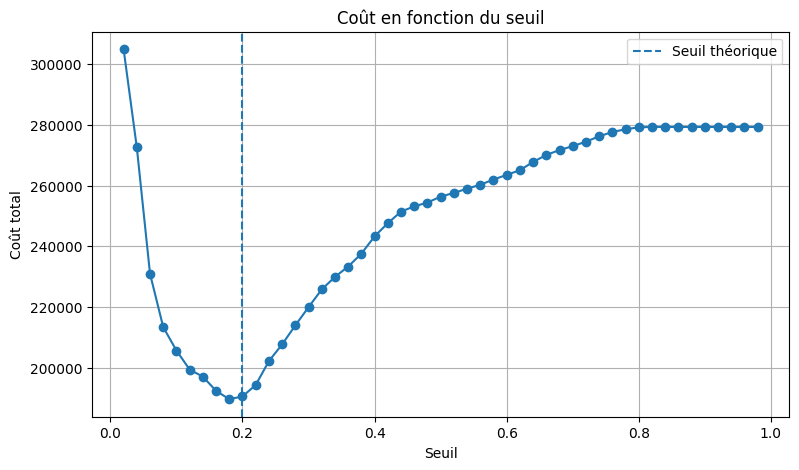

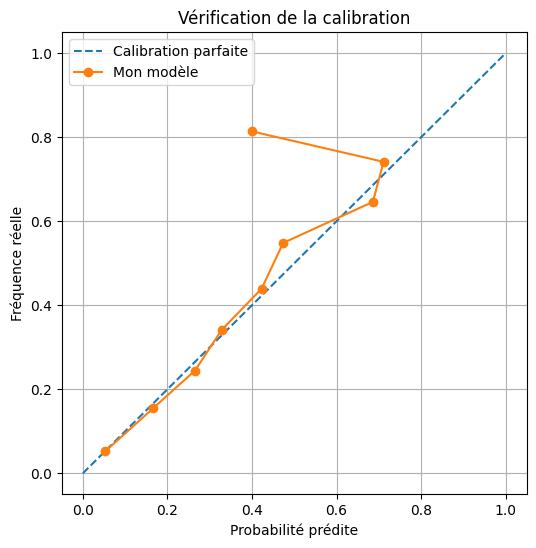

Seuil choisi : 0.18
Coût au seuil choisi : 189550
Coût au seuil 0,50 : 256350
Seuil théorique : 0.2
Écart entre seuil choisi et seuil théorique : 0.020000000000000018
Écart moyen de calibration : 0.0689559336032475
Au seuil de 0,50, l'exactitude est de 81.95 %, mais le coût réel est de 256350 unités. L'exactitude ne tient pas compte du prix différent des fausses alertes et des absences manquées.
  ok        un seuil écrit entre 0 et 1
  ok        deux coûts, des entiers positifs
  ok        l’écart est argumenté


In [90]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.calibration import calibration_curve

seuils = np.arange(0.02, 1.00, 0.02)

couts = []

for seuil in seuils:
    decisions = (proba_perso > seuil).astype(int)
    couts.append(cout(decisions, verite=yval_perso))

plt.figure(figsize=(9, 5))
plt.plot(seuils, couts, marker="o")
plt.axvline(COUT_FP / (COUT_FP + COUT_FN), linestyle="--", label="Seuil théorique")
plt.xlabel("Seuil")
plt.ylabel("Coût total")
plt.title("Coût en fonction du seuil")
plt.legend()
plt.grid()
plt.show()

indice_min = int(np.argmin(couts))
mon_seuil_choisi = float(seuils[indice_min])
cout_a_mon_seuil = int(couts[indice_min])

decisions_defaut = (proba_perso > 0.5).astype(int)
cout_du_seuil_par_defaut = int(cout(decisions_defaut, verite=yval_perso))

exactitude_perso = 100 * accuracy_score(yval_perso, decisions_defaut)

ecart_metrique_cout = (
    f"Au seuil de 0,50, l'exactitude est de {exactitude_perso:.2f} %, "
    f"mais le coût réel est de {cout_du_seuil_par_defaut} unités. "
    "L'exactitude ne tient pas compte du prix différent des fausses alertes "
    "et des absences manquées."
)

seuil_theorique = COUT_FP / (COUT_FP + COUT_FN)

probabilites_moyennes, frequences_reelles = calibration_curve(
    yval_perso, proba_perso, n_bins=10
)

ecart_calibration = np.mean(
    np.abs(probabilites_moyennes - frequences_reelles)
)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibration parfaite")
plt.plot(probabilites_moyennes, frequences_reelles, marker="o", label="Mon modèle")
plt.xlabel("Probabilité prédite")
plt.ylabel("Fréquence réelle")
plt.title("Vérification de la calibration")
plt.legend()
plt.grid()
plt.show()

print("Seuil choisi :", mon_seuil_choisi)
print("Coût au seuil choisi :", cout_a_mon_seuil)
print("Coût au seuil 0,50 :", cout_du_seuil_par_defaut)
print("Seuil théorique :", seuil_theorique)
print("Écart entre seuil choisi et seuil théorique :", abs(mon_seuil_choisi - seuil_theorique))
print("Écart moyen de calibration :", ecart_calibration)
print(ecart_metrique_cout)

controle('un seuil écrit entre 0 et 1', lambda: 0 < mon_seuil_choisi < 1, 'un seuil entre 0 et 1')

controle('deux coûts, des entiers positifs',
lambda: cout_a_mon_seuil >= 0 and cout_du_seuil_par_defaut >= 0
and int(cout_a_mon_seuil) == cout_a_mon_seuil,
'le coût est un entier, en unités de coût')

controle('l’écart est argumenté', lambda: len(ecart_metrique_cout) > 40,
'chiffrez l’écart, et nommez les deux métriques comparées')

### Question 12 — Les deux classements  ·  *carnet J4*  ·  *cœur*


**Contexte.** Le classement affiché se fait sur l'**exactitude** ; le cours vient de montrer que la décision
se paie en **coût**. Les deux classements ne désignent donc pas la même tête.

**Consigne.**
  1. prenez **deux stratégies** au moins sur votre échantillon (par exemple *n'alerte jamais*, et le
     modèle à deux seuils différents) ;
  2. classez-les deux fois, du meilleur au moins bon : par **exactitude**, puis par **coût** ;
  3. dites si la tête change, et ce que cela coûte de se fier à la métrique affichée.

**Livrables.** `classement_exactitude` · `classement_cout` · `tete_change`.

**Critère de réussite.** Deux stratégies suffisent : ce qui compte est que les deux classements
soient **mesurés sur la même population**.

*≈ 15 min.*


In [91]:
from sklearn.metrics import accuracy_score

strategies = {
    "Ne jamais alerter": np.zeros(len(yval_perso), dtype=int),
    "Modèle seuil 0.40": (proba_perso > 0.40).astype(int),
    "Modèle seuil 0.50": (proba_perso > 0.50).astype(int)
}

resultats = []

for nom, decisions in strategies.items():
    exactitude = accuracy_score(yval_perso, decisions) * 100
    cout_total = cout(decisions, verite=yval_perso)

    resultats.append({
        "strategie": nom,
        "exactitude": exactitude,
        "cout": cout_total
    })

classement_exactitude = sorted(
    [(r["strategie"], r["exactitude"]) for r in resultats],
    key=lambda x: x[1],
    reverse=True
)

classement_cout = sorted(
    [(r["strategie"], r["cout"]) for r in resultats],
    key=lambda x: x[1]
)

tete_change = (
    f"Par exactitude, la meilleure stratégie est {classement_exactitude[0][0]} "
    f"avec {classement_exactitude[0][1]:.2f} %. "
    f"Par coût, la meilleure stratégie est {classement_cout[0][0]} "
    f"avec {classement_cout[0][1]} unités de coût. "
    f"La tête change : {classement_exactitude[0][0] != classement_cout[0][0]}. "
    "Se fier uniquement à l'exactitude peut conduire à choisir une stratégie "
    "qui coûte davantage."
)

print("Classement par exactitude :")
for element in classement_exactitude:
    print(element)

print("\nClassement par coût :")
for element in classement_cout:
    print(element)

print("\nConclusion :", tete_change)

controle('deux classements', lambda: len(classement_exactitude) >= 2 and len(classement_cout) >= 2,
'deux stratégies au moins, classées deux fois')

controle('la réponse est argumentée', lambda: len(str(tete_change)) > 40,
'dites si la tête change, et pourquoi')

Classement par exactitude :
('Modèle seuil 0.50', 81.94796531020681)
('Modèle seuil 0.40', 81.4609739826551)
('Ne jamais alerter', 81.36757838559039)

Classement par coût :
('Modèle seuil 0.40', 243250)
('Modèle seuil 0.50', 256350)
('Ne jamais alerter', 279300)

Conclusion : Par exactitude, la meilleure stratégie est Modèle seuil 0.50 avec 81.95 %. Par coût, la meilleure stratégie est Modèle seuil 0.40 avec 243250 unités de coût. La tête change : True. Se fier uniquement à l'exactitude peut conduire à choisir une stratégie qui coûte davantage.
  ok        deux classements
  ok        la réponse est argumentée


## Ce qu’on rend, et pourquoi ce format

**Trois tableaux**, comme au devoir 1 :

- **le tableau à quatre colonnes** — modèle · validation · affiché · écart — et vos trois phrases ;
- **le journal de nettoyage** — une ligne par décision : la décision, le choix fait, l’effet mesuré ;
- **le tableau d’essais** — une ligne par changement, avec l’attendu (un signe et une raison) et le
  mesuré.

Les **constats chiffrés** et les **hypothèses de features** appartiennent au **devoir 1**. Les
questions d’ici portent sur les baselines, le nettoyage et la mesure. Les tableaux qui les
portent sont ceux-ci. **Vos métriques, vos aires et votre seuil** (Q10, Q11) se lisent dans les cellules qui
les produisent.

La cellule qui suit affiche **les trois tableaux** remplis automatiquement, tels que vous les rendez.


In [30]:
print("vos essais \n")
display(pd.DataFrame(ESSAIS))
print("votre journal de nettoyage \n")
display(pd.DataFrame(JOURNAL))
print("votre tableau à quatre colonnes \n")
try:
    tableau_quatre_colonnes = mon_tableau
except NameError:
    tableau_quatre_colonnes = pd.DataFrame()
display(tableau_quatre_colonnes)
print("vos contrôles \n")
display(pd.DataFrame(VERIFICATIONS))


vos essais 



""


votre journal de nettoyage 



""


votre tableau à quatre colonnes 



""


vos contrôles 



,contrôle,tient
0,les données sont chargées,True
1,la table de travail est construite,True
2,"le découpage est fait, le modèle ajusté",True
3,les baselines sont mesurées,True
4,votre échantillon personnel est prêt,True
5,le pipeline tourne sur une table brute,True
6,le fichier est écrit,True
7,votre échantillon personnel est construit,True


## Rendre le travail

1. **Exécutez tout** le carnet (`Run All`), pour que les tableaux soient remplis.
2. **Déposez** ce carnet dans votre dépôt GitHub personnel. Mettez **avec** lui votre déclaration d’usage de
   l’IA, dans le **même commit** :
   - téléchargez le modèle **`DECLARATION_modele.md`** depuis le **dépôt du cours** ;
   - recopiez-le dans votre dépôt sous le nom **`declaration_DM2.md`** ;
   - remplissez-le : les deux scores, ce que vous avez produit seul, ce que vous avez fait
     avec un assistant, et ce que vous ne sauriez pas expliquer.
3. Vérifiez que le lien de votre dépôt est bien à jour dans le formulaire de la classe.

> Un travail non déposé n’existe pas.
